## Libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from scipy import stats
import seaborn as sns

## Paths

In [5]:
### INPUT ###
conc_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Data\AVP2016_concentrations_data.xlsx"
conc_data = pd.read_excel(conc_path)

phyto_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Data\AVP2016_phytoplankton_data.xlsx"
phyto_data = pd.read_excel(phyto_path)

In [6]:
### OUTPUT ###
output_dir = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results"
file_name = "POC-SA_relation"

## Calculations

In [9]:
rows = len(conc_data['date'])-3   # -3 because the columns include 3 NaN values on the bottom rows otherwise.
SA_tot = [0] * rows
SA_tot_m2L = [0]*rows
BV_tot = [0] * rows

for i in range(rows): # Loop over each row in conc_data
    date = conc_data['date'][i]    # To collect the timestamp
    
    for j in range(len(phyto_data['per cel'])):             # Loop over each row index in phyto_data
        if phyto_data['monsterdatum'][j] == date:       # If the the timestamps of both datasets are the same, calculate SA
            BV = phyto_data['per cel'][j]            # Biovolume of one cell in µm3
            r = ((0.75*BV)/np.pi)**(1/3)             # Radius of one cell in µm
            SA = 4 * np.pi * r**2                   # Surface area of one cell in µm2
            cells_per_L = phyto_data['cel/ml'][j] *1000  # Convert cells/mL to cells/L
            SA_tot[i] += SA * cells_per_L    #  Sum of the total surface area for all species at a specific time, in µm2/L
            SA_tot_m2L[i] = SA_tot[i]*10**-12  # in m2/L
            BV_tot[i] += BV * cells_per_L    #  Sum of the total biovolume for all species at a specific time, in µm3/L

data = {
    "POC": conc_data['POC'][:rows],                 # umol/L
    "POC_molL": conc_data['POC'][:rows] * 1E-6,     # mol/L
    "SA": SA_tot,                                   # µm2/L
    "SA_m2L": SA_tot_m2L,                           # m2/L
    "BV_tot": BV_tot,                               # Total biovolume from phyto_data , µm3/L
    "biovolume": conc_data['biovolume'][:rows],     # Biovolume from conc_data, µm3/L
    "date": conc_data['date'][:rows]
}

df = pd.DataFrame(data)

## Correlations

Text(0.5, 0, 'date')

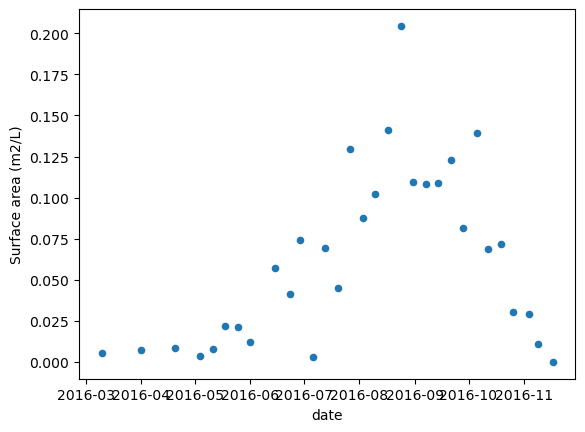

In [43]:
plot = df.plot(kind='scatter', x='date', y='SA_m2L')
plot.set_ylabel('Surface area (m2/L)')
plot.set_xlabel('date')

Linear correlation: 0.8053393669477708
Nonlinear correlation: 0.8189516129032259
Nonparametric correlation: 0.6559139784946237


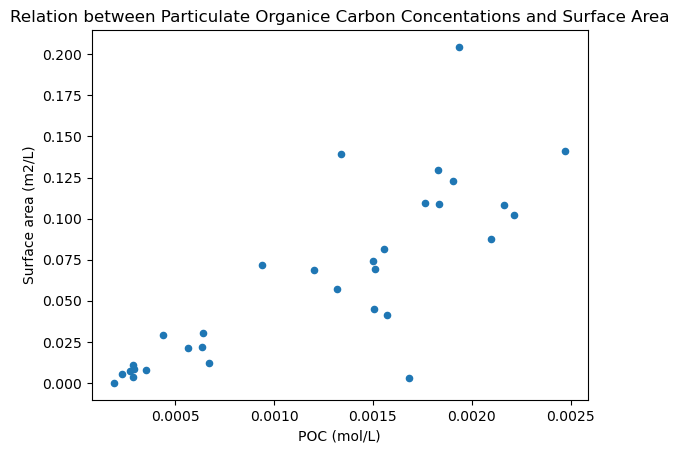

Formula: SA = -9676578268.9879 + 59799917.2901 * POC
R² = 0.6486
p-value = 0.0000
  
Formula: SA = -0.0097 + 59.799917290081886 * POC
R² = 0.6486
p-value = 0.0000


In [45]:
### Correlations ###
lin_cor = df['SA'].corr(df['POC'])                         # Linear correlation using Pearson's coefficient
nonlin_cor = df['SA'].corr(df['POC'], method='spearman')   # Nonlinear correlation using Spearman's rank coefficient
nonpara_cor = df['SA'].corr(df['POC'], method='kendall')   # Nonparametric measure using Kendall's Tau correlation coefficient

print(f'Linear correlation: {lin_cor}')
print(f'Nonlinear correlation: {nonlin_cor}')
print(f'Nonparametric correlation: {nonpara_cor}')

### Plotting ###
plot = df.plot(kind='scatter', x='POC_molL', y='SA_m2L')
plot.set_ylabel('Surface area (m2/L)')
plot.set_xlabel('POC (mol/L)')
plt.title("Relation between Particulate Organice Carbon Concentations and Surface Area")

### Saving ###
# out = os.path.join(output_dir, f"Plots\\{file_name}.png")
# plt.savefig(out)
###############
plt.show()

#### linear regression ###
slope, intercept, r_value, p_value, std_err = stats.linregress(df['POC'].values, df['SA'].values)

print(f"Formula: SA = {intercept:.4f} + {slope:.4f} * POC")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

print("  ") 

slope, intercept, r_value, p_value, std_err = stats.linregress(df['POC_molL'].values, df['SA_m2L'].values)
print(f"Formula: SA = {intercept:.4f} + {slope} * POC")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

Linear correlation: 0.7769242759785485
Nonlinear correlation: 0.8189516129032259
Nonparametric correlation: 0.6559139784946237


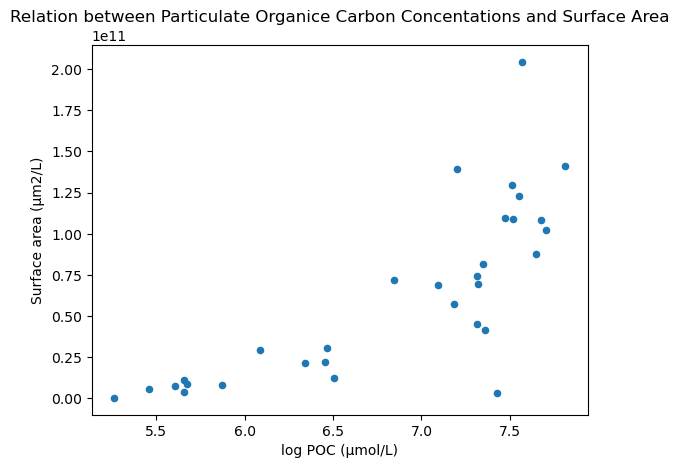

Formula: SA = -287342527584.6434 + 51116214760.5921 * POC
R² = 0.6036
p-value = 0.0000


In [66]:
df['log_POC'] = np.log(df['POC'])

### Correlations ###
lin_cor = df['SA'].corr(df['log_POC'])                         # Linear correlation using Pearson's coefficient
nonlin_cor = df['SA'].corr(df['log_POC'], method='spearman')   # Nonlinear correlation using Spearman's rank coefficient
nonpara_cor = df['SA'].corr(df['log_POC'], method='kendall')   # Nonparametric measure using Kendall's Tau correlation coefficient

print(f'Linear correlation: {lin_cor}')
print(f'Nonlinear correlation: {nonlin_cor}')
print(f'Nonparametric correlation: {nonpara_cor}')

### Plotting ###
plot = df.plot(kind='scatter', x='log_POC', y='SA')
plot.set_ylabel('Surface area (µm2/L)')
plot.set_xlabel('log POC (µmol/L)')
plt.title("Relation between Particulate Organice Carbon Concentations and Surface Area")

### Saving ###
# out = os.path.join(output_dir, f"Plots\\lognormalized_{file_name}.png")
# plt.savefig(out)
###############
plt.show()

#### linear regression ###
slope, intercept, r_value, p_value, std_err = stats.linregress(df['log_POC'].values, df['SA'].values)

print(f"Formula: SA = {intercept:.4f} + {slope:.4f} * POC")
print(f"R² = {r_value**2:.4f}")
print(f"p-value = {p_value:.4f}")

## Final plot

In [23]:
lin_cor = df['SA_m2L'].corr(df['POC_molL'])                         # Linear correlation using Pearson's coefficient
print(f'Linear correlation: {lin_cor}')

Linear correlation: 0.8053393669477708


Linear correlation: 0.8053393669477708


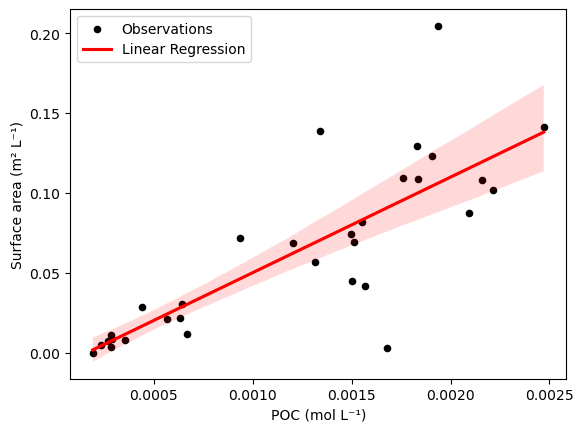

In [12]:
### Correlations ###
lin_cor = df['SA'].corr(df['POC'])                         # Linear correlation using Pearson's coefficient
print(f'Linear correlation: {lin_cor}')

### Plotting ###
plot = df.plot(kind='scatter', x='POC_molL', y='SA_m2L', label='Observations', color='black')

sns.regplot(data=df, x='POC_molL', y='SA_m2L', ax=plot, scatter=False, color='red', ci=95, label='Linear Regression')

plot.set_ylabel('Surface area (m² L⁻¹)')
plot.set_xlabel('POC (mol L⁻¹)')
# plt.title("Relation between POC and Surface Area")
plot.legend()

## Saving ###
out = os.path.join(output_dir, f"Plots\\{file_name}.png")
plt.savefig(out)
##############


plt.show()